In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import datetime as dt

import glob
import geopandas as gpd
#import pyprojtfg

import matplotlib.pyplot as plt


In [2]:
import rasterio as rio
import rioxarray as rx

In [3]:
# iSnobal outputs for Apr 21st and May 18th 2022

sd_toposplit_dsw3_20220421 = xr.load_dataset('/uufs/chpc.utah.edu/common/home/uvu-group1/olson/snow-data/results/isnobal_simulations/hrrr_toposplit/erw_spires_dsw3_dlwrf/wy2022/erw_50m/run20220421/snow.nc')
sd_toposplit_dsw3_20220518 = xr.load_dataset('/uufs/chpc.utah.edu/common/home/uvu-group1/olson/snow-data/results/isnobal_simulations/hrrr_toposplit/erw_spires_dsw3_dlwrf/wy2022/erw_50m/run20220518/snow.nc')

sd_toposplit_dsw1_20220421 = xr.load_dataset('/uufs/chpc.utah.edu/common/home/uvu-group1/olson/snow-data/results/isnobal_simulations/hrrr_toposplit/erw_spires_dsw1_dlwrf/wy2022/erw_50m/run20220421/snow.nc')
sd_toposplit_dsw1_20220518 = xr.load_dataset('/uufs/chpc.utah.edu/common/home/uvu-group1/olson/snow-data/results/isnobal_simulations/hrrr_toposplit/erw_spires_dsw1_dlwrf/wy2022/erw_50m/run20220518/snow.nc')

sd_toposplit_dsw3h_20220421 = xr.load_dataset('/uufs/chpc.utah.edu/common/home/uvu-group1/olson/snow-data/results/isnobal_simulations/hrrr_toposplit/erw_spires_dsw3h_dlwrf/wy2022/erw_50m/run20220421/snow.nc')
sd_toposplit_dsw3h_20220518 = xr.load_dataset('/uufs/chpc.utah.edu/common/home/uvu-group1/olson/snow-data/results/isnobal_simulations/hrrr_toposplit/erw_spires_dsw3h_dlwrf/wy2022/erw_50m/run20220518/snow.nc')


In [4]:
sd_toposplit_dsw3_20220421.thickness

<xarray.DataArray 'thickness' (time: 1, y: 837, x: 656)> Size: 2MB
array([[[2.018514  , 2.0913095 , 2.1510181 , ..., 1.1359581 ,
         1.1143612 , 1.0809114 ],
        [1.9835502 , 2.0672166 , 2.140422  , ..., 1.1553836 ,
         1.1380253 , 1.1082257 ],
        [1.9693413 , 2.0609317 , 2.116579  , ..., 1.044596  ,
         1.1362268 , 1.115689  ],
        ...,
        [0.03595794, 0.03006796, 0.08756123, ..., 0.        ,
         0.        , 0.        ],
        [0.43334445, 0.48686665, 0.548641  , ..., 0.        ,
         0.        , 0.        ],
        [0.64510703, 0.67815304, 0.6741448 , ..., 0.        ,
         0.        , 0.        ]]], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 8B 2022-04-21T22:00:00
  * y        (y) float32 3kB 4.323e+06 4.323e+06 ... 4.281e+06 4.281e+06
  * x        (x) float32 3kB 3.159e+05 3.16e+05 3.16e+05 ... 3.486e+05 3.487e+05
Attributes:
    units:         m
    description:   Predicted thickness of the snowcover
    grid_mapping:  projection

In [5]:
aso_data_20220421 = rx.open_rasterio('/uufs/chpc.utah.edu/common/home/skiles-group3/ASO/CO/ASO_Gunnison_East_2022Apr21_AllData_and_Reports/ASO_Gunnison_East_2022Apr21_AllData_and_Reports/ASO_Gunnison_East_2022Apr21_AllData_and_Reports/ASO_Gunnison_EastRiver_2022Apr21_snowdepth_50m.tif')
aso_data_20220518 = rx.open_rasterio('/uufs/chpc.utah.edu/common/home/skiles-group3/ASO/CO/ASO_EastRiver_2022May18_AllData_and_Reports/ASO_EastRiver_Mosaic_2022May18_snowdepth_50m.tif')


In [6]:
aso_data_20220421

<xarray.DataArray (band: 1, y: 995, x: 809)> Size: 3MB
[804955 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 6kB 3.081e+05 3.081e+05 ... 3.484e+05 3.485e+05
  * y            (y) float64 8kB 4.322e+06 4.322e+06 ... 4.273e+06 4.273e+06
    spatial_ref  int64 8B 0
Attributes:
    Band_1:         ASO Depth [m]
    AREA_OR_POINT:  Area
    _FillValue:     nan
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ASO Depth [m]

In [7]:
# ASO snowdepth maps for Apr 21st and May 18th 2022
# aso_data_20220421 = xr.load_dataset('/uufs/chpc.utah.edu/common/home/skiles-group3/ASO/CO/ASO_Gunnison_East_2022Apr21_AllData_and_Reports/ASO_Gunnison_East_2022Apr21_AllData_and_Reports/ASO_Gunnison_East_2022Apr21_AllData_and_Reports/ASO_Gunnison_EastRiver_2022Apr21_snowdepth_50m.tif')
# aso_data_20220518 = xr.load_dataset('/uufs/chpc.utah.edu/common/home/skiles-group3/ASO/CO/ASO_EastRiver_2022May18_AllData_and_Reports/ASO_EastRiver_Mosaic_2022May18_snowdepth_50m.tif')

# Shapefile of the East River, great to have it for plotting
erw_shp = gpd.read_file('/uufs/chpc.utah.edu/common/home/skiles-group3/jmhu/ancillary/polys/erw_basin_outline_HUC10_32613.shp')

In [8]:
# A bit of cleaning, renaming

# def aso_data_adjustements(aso_data, date):

#     aso_data = aso_data.rename_vars({'band_data': 'snow_depth'})
#     aso_data = aso_data.squeeze(dim="band", drop=True)  
#     aso_data = aso_data.expand_dims(time=[date])

#     return aso_data

def aso_data_adjustements(aso_data, date):
    aso_data = aso_data.rename("snow_depth")  # Rename DataArray itself
    aso_data = aso_data.squeeze(dim="band", drop=True)  
    aso_data = aso_data.expand_dims(time=[date])
    return aso_data


aso_data_20220421 = aso_data_adjustements(aso_data_20220421, dt.datetime(2022,4,21))
aso_data_20220518 = aso_data_adjustements(aso_data_20220518, dt.datetime(2022,5,18))

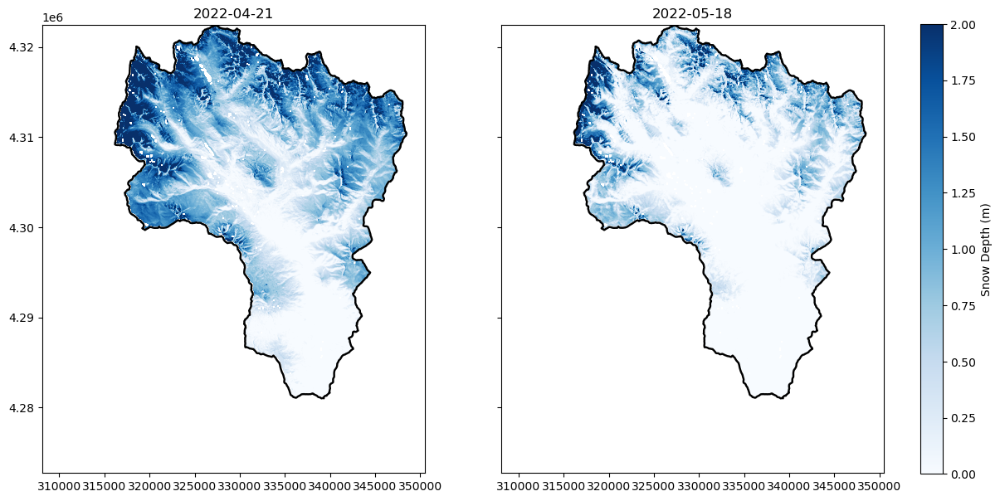

In [9]:
# Visualizing both ASO days

aso_data = [aso_data_20220421, aso_data_20220518]

fig, axs = plt.subplots(1, 2, figsize=(14,9), sharey=True)
axs=axs.ravel()

# 20220421
extent=[aso_data[0].x.min(), aso_data[0].x.max(),
        aso_data[0].y.min(),aso_data[0].y.max()]
axs[0].set_title(pd.to_datetime(aso_data[0].time.values[0]).strftime('%Y-%m-%d'))
# img = axs[0].imshow(aso_data[0].snow_depth.isel(time=0), vmin=0, vmax=2.0, cmap='Blues', extent=extent)
img = axs[0].imshow(aso_data[0].isel(time=0),  vmin=0, vmax=2.0, cmap='Blues', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)

# 20220518
extent=[aso_data[1].x.min(), aso_data[1].x.max(),
        aso_data[1].y.min(),aso_data[1].y.max()]
axs[1].set_title(pd.to_datetime(aso_data[1].time.values[0]).strftime('%Y-%m-%d'))
# img = axs[1].imshow(aso_data[1].snow_depth.isel(time=0), vmin=0, vmax=2.0, cmap='Blues', extent=extent)
img = axs[1].imshow(aso_data[1].isel(time=0), vmin=0, vmax=2.0, cmap='Blues', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)

# Shared colorbar
cbar = fig.colorbar(img, ax=axs, orientation='vertical', fraction=0.025, pad=0.04)
cbar.set_label('Snow Depth (m)')
#fig.tight_layout()

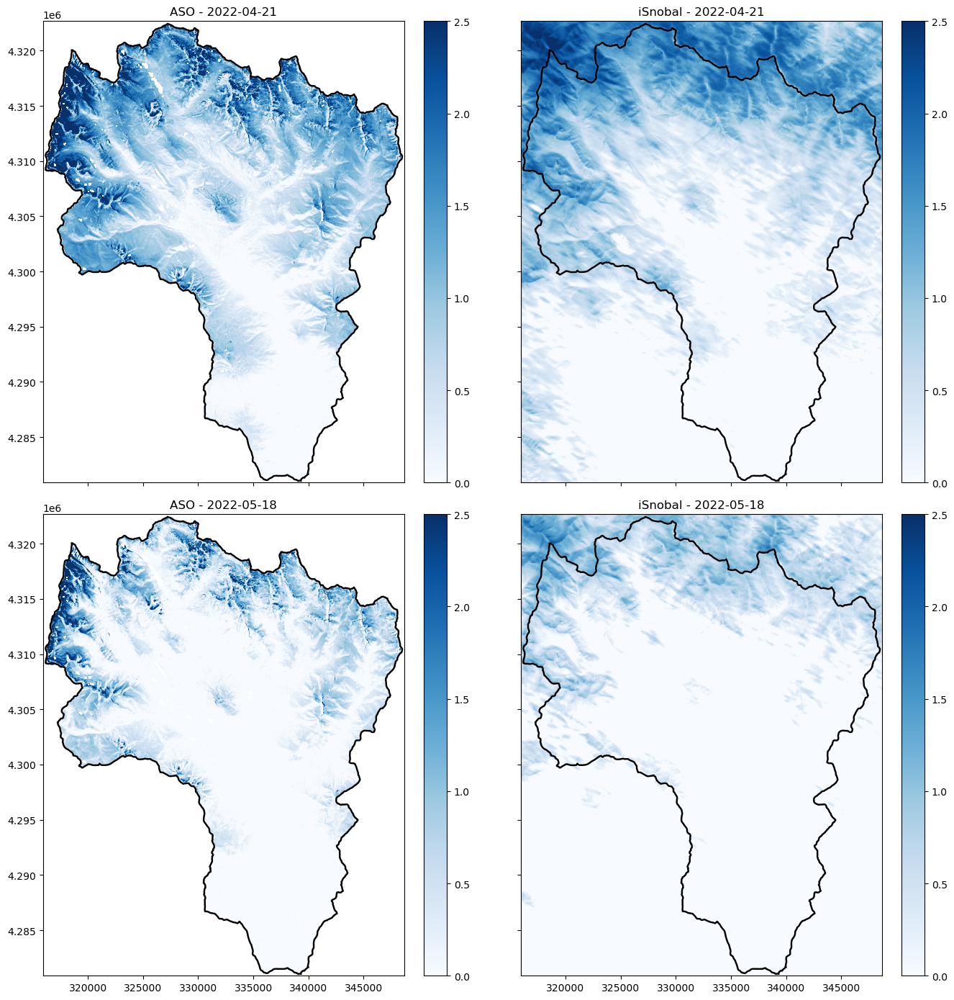

In [10]:
# Visualizing both days

fig, axs = plt.subplots(2,2, figsize=(14, 14), sharey=True, sharex=True)
axs=axs.ravel()
vmin, vmax = 0, 2.5

# 20220421
extent=[aso_data[0].x.min(), aso_data[0].x.max(),
        aso_data[0].y.min(),aso_data[0].y.max()]
axs[0].set_title('ASO - '+pd.to_datetime(aso_data[0].time.values[0]).strftime('%Y-%m-%d'))
# img1 = axs[0].imshow(aso_data[0].snow_depth.isel(time=0), vmin=vmin, vmax=vmax, cmap='Blues', extent=extent)
img1 = axs[0].imshow(aso_data[0].isel(time=0),  vmin=vmin, vmax=vmax, cmap='Blues', extent=extent)

erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

extent=[sd_toposplit_dsw3_20220421.x.min(), sd_toposplit_dsw3_20220421.x.max(),
        sd_toposplit_dsw3_20220421.y.min(),sd_toposplit_dsw3_20220421.y.max()]
axs[0].set_xlim(extent[0], extent[1])
axs[0].set_ylim(extent[2], extent[3])

axs[1].set_title('iSnobal - '+pd.to_datetime(aso_data[0].time.values[0]).strftime('%Y-%m-%d'))
img2 = axs[1].imshow(sd_toposplit_dsw3_20220421.thickness.isel(time=0), vmin=vmin, vmax=vmax, cmap='Blues', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img2, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04)

# 20220518
extent=[aso_data[1].x.min(), aso_data[1].x.max(),
        aso_data[1].y.min(),aso_data[1].y.max()]
axs[2].set_title('ASO - '+pd.to_datetime(aso_data[1].time.values[0]).strftime('%Y-%m-%d'))
# img3 = axs[2].imshow(aso_data[1].snow_depth.isel(time=0), vmin=vmin, vmax=vmax, cmap='Blues', extent=extent)
img3 = axs[2].imshow(aso_data[1].isel(time=0),  vmin=vmin, vmax=vmax, cmap='Blues', extent=extent)
erw_shp.boundary.plot(ax=axs[2], color='k', linewidth=1.75)
fig.colorbar(img3, ax=axs[2], orientation='vertical', fraction=0.056, pad=0.04)

extent=[sd_toposplit_dsw3_20220518.x.min(), sd_toposplit_dsw3_20220518.x.max(),
        sd_toposplit_dsw3_20220518.y.min(),sd_toposplit_dsw3_20220518.y.max()]
axs[2].set_xlim(extent[0], extent[1])
axs[2].set_ylim(extent[2], extent[3])

axs[3].set_title('iSnobal - '+pd.to_datetime(aso_data[1].time.values[0]).strftime('%Y-%m-%d'))
img4 = axs[3].imshow(sd_toposplit_dsw3_20220518.thickness.isel(time=0), vmin=vmin, vmax=vmax, cmap='Blues', extent=extent)
erw_shp.boundary.plot(ax=axs[3], color='k', linewidth=1.75)
fig.colorbar(img4, ax=axs[3], orientation='vertical', fraction=0.056, pad=0.04)

fig.tight_layout()


In [11]:
# Comparison starts here

In [11]:
# Ensure datasets have CRS

aso_data_20220421 = aso_data_20220421.rio.write_crs("EPSG:32613")  # Assign CRS if missing
aso_data_20220518 = aso_data_20220518.rio.write_crs("EPSG:32613")  

sd_toposplit_dsw3_20220421 = sd_toposplit_dsw3_20220421.rio.write_crs("EPSG:32613") 
sd_toposplit_dsw3_20220518 = sd_toposplit_dsw3_20220518.rio.write_crs("EPSG:32613") 
sd_toposplit_dsw1_20220421 = sd_toposplit_dsw1_20220421.rio.write_crs("EPSG:32613") 
sd_toposplit_dsw1_20220518 = sd_toposplit_dsw1_20220518.rio.write_crs("EPSG:32613") 
sd_toposplit_dsw3h_20220421 = sd_toposplit_dsw3h_20220421.rio.write_crs("EPSG:32613") 
sd_toposplit_dsw3h_20220518 = sd_toposplit_dsw3h_20220518.rio.write_crs("EPSG:32613") 

# Reproject iSnobal dataset to match aso_data
sd_toposplit_dsw3_20220421_repr = sd_toposplit_dsw3_20220421.rio.reproject_match(aso_data_20220421)
sd_toposplit_dsw3_20220518_repr = sd_toposplit_dsw3_20220518.rio.reproject_match(aso_data_20220518)
sd_toposplit_dsw1_20220421_repr = sd_toposplit_dsw1_20220421.rio.reproject_match(aso_data_20220421)
sd_toposplit_dsw1_20220518_repr = sd_toposplit_dsw1_20220518.rio.reproject_match(aso_data_20220518)
sd_toposplit_dsw3h_20220421_repr = sd_toposplit_dsw3h_20220421.rio.reproject_match(aso_data_20220421)
sd_toposplit_dsw3h_20220518_repr = sd_toposplit_dsw3h_20220518.rio.reproject_match(aso_data_20220518)

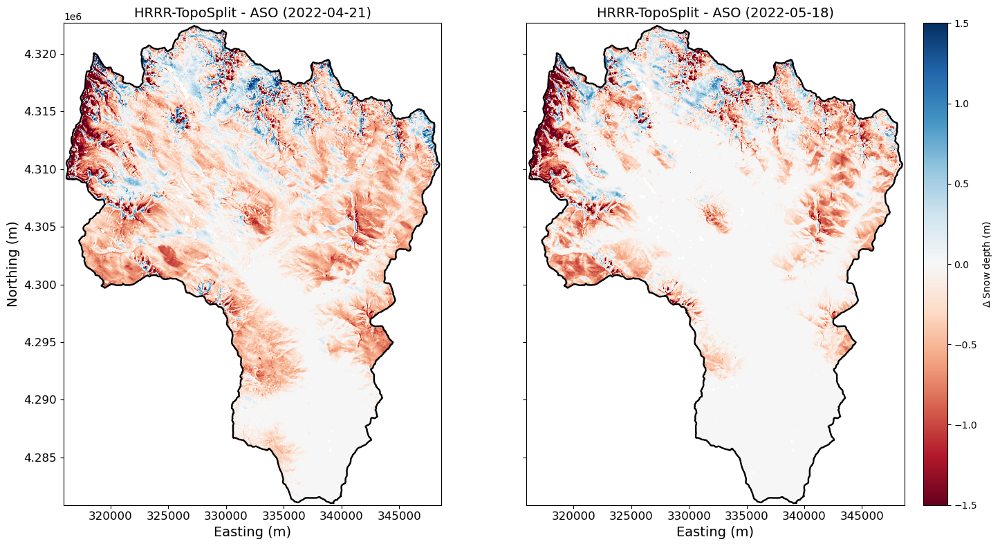

In [12]:
fig, axs = plt.subplots(1,2, figsize=(15, 8), sharey=True)
axs=axs.ravel()

vmin, vmax = -1.5, 1.5
extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
        aso_data_20220421.y.min(),aso_data_20220421.y.max()]

axs[0].set_title('HRRR-TopoSplit - ASO ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img0 = axs[0].imshow(sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
img0 = axs[0].imshow(sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0),
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
# fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

axs[1].set_title('HRRR-TopoSplit - ASO ('+pd.to_datetime(aso_data_20220518.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img1 = axs[1].imshow(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
img1 = axs[1].imshow(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0),
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Snow depth (m)')

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

axs[0].set_ylabel("Northing (m)", fontsize=14)

for ax in axs:
    ax.set_xlabel("Easting (m)", fontsize=14)

# For better visualization
for ax in axs:
    ax.set_xlim(sd_toposplit_dsw3_20220518.x.min(), sd_toposplit_dsw3_20220518.x.max())
    ax.set_ylim(sd_toposplit_dsw3_20220518.y.min(), sd_toposplit_dsw3_20220518.y.max())


fig.tight_layout()

# svpth = "/uufs/chpc.utah.edu/common/home/u1037042/Documents/figures-2025/topo-split-rmgsa/"
# plt.savefig(svpth + 'aso-comp-dsw3.png', dpi=300, bbox_inches='tight')

/scratch/local/u1037042/4416532/ipykernel_1662926/3823118394.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=bias_df, x='Date', y='Bias', palette='RdBu', ax=ax)
/scratch/local/u1037042/4416532/ipykernel_1662926/3823118394.py:21: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(data=bias_df, x='Date', y='Bias', estimator=np.mean, color='black', ax=ax, markers='o', errorbar=None, join=False)


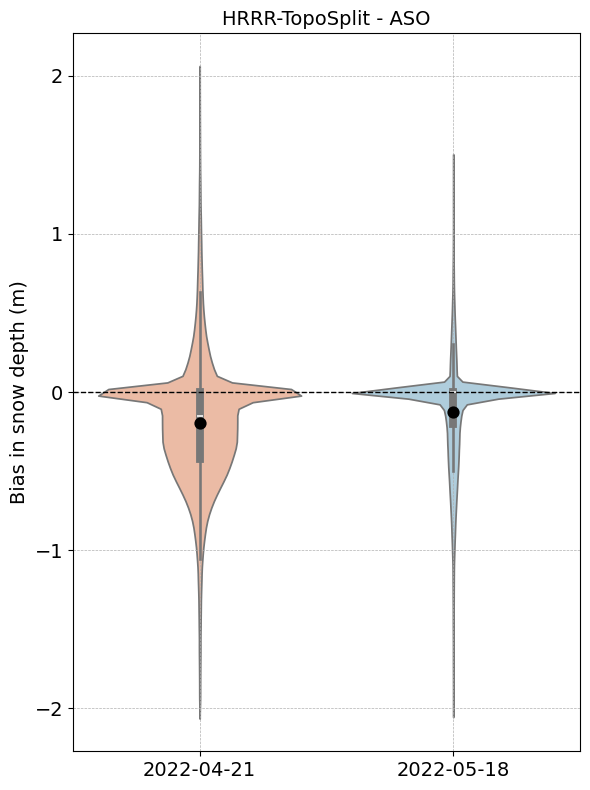

In [13]:
import seaborn as sns

# Calculate bias (Model - Observed) and flatten to 1D
bias_20220421 = (sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0)).values.flatten()
bias_20220518 = (sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0)).values.flatten()

import pandas as pd

# Combine into a single DataFrame
bias_df = pd.DataFrame({
    'Bias': np.concatenate([bias_20220421, bias_20220518]),
    'Date': ['2022-04-21'] * len(bias_20220421) + ['2022-05-18'] * len(bias_20220518)
})

bias_df = bias_df[(bias_df['Bias'] >= -2) & (bias_df['Bias'] <= 2)]

fig, ax = plt.subplots(figsize=(6, 8))

sns.violinplot(data=bias_df, x='Date', y='Bias', palette='RdBu', ax=ax)
ax.axhline(0, color='k', linestyle='--', linewidth=1)
sns.pointplot(data=bias_df, x='Date', y='Bias', estimator=np.mean, color='black', ax=ax, markers='o', errorbar=None, join=False)
ax.set_title("HRRR-TopoSplit - ASO", fontsize=14)
ax.set_ylabel("Bias in snow depth (m)", fontsize=14)
ax.set_xlabel("", fontsize=14)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.show()
# svpth = "/uufs/chpc.utah.edu/common/home/u1037042/Documents/figures-2025/topo-split-rmgsa/"
# plt.savefig(svpth + 'aso-comp-dsw3-stats.png', dpi=300, bbox_inches='tight')

In [20]:
bias_df.groupby('Date').mean()
# bias_df.groupby('Date').median()

,Bias
Date,
2022-04-21,-0.196009
2022-05-18,-0.123936


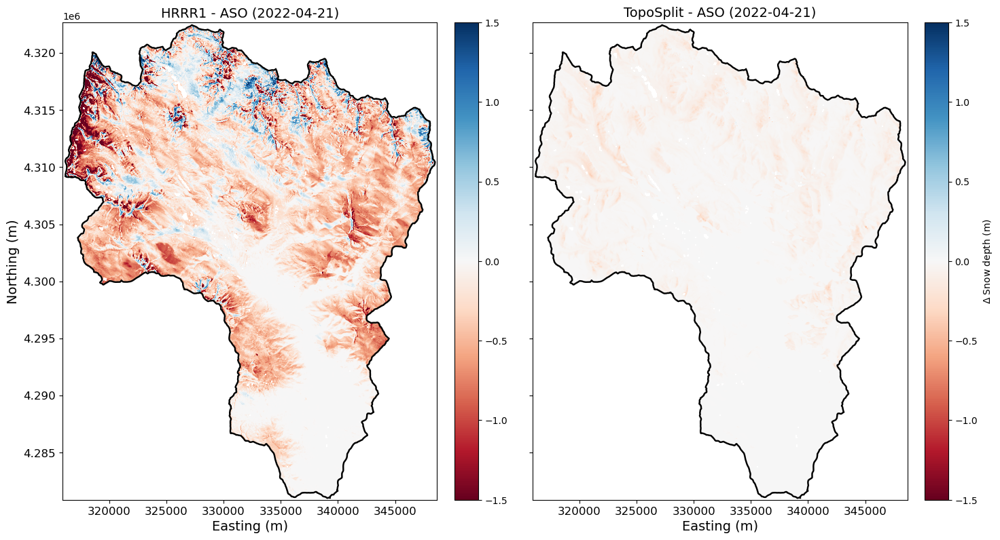

In [14]:
fig, axs = plt.subplots(1,2, figsize=(15, 8), sharey=True)
axs=axs.ravel()

vmin, vmax = -1.5, 1.5
extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
        aso_data_20220421.y.min(),aso_data_20220421.y.max()]

axs[0].set_title('HRRR1 - ASO ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img0 = axs[0].imshow(sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
img0 = axs[0].imshow(sd_toposplit_dsw1_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0),
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

axs[1].set_title('TopoSplit - ASO ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img1 = axs[1].imshow(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)

diff_all = (sd_toposplit_dsw1_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0)) - (sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0))

img1 = axs[1].imshow(diff_all,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Snow depth (m)')

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

axs[0].set_ylabel("Northing (m)", fontsize=14)

for ax in axs:
    ax.set_xlabel("Easting (m)", fontsize=14)

# For better visualization
for ax in axs:
    ax.set_xlim(sd_toposplit_dsw3_20220518.x.min(), sd_toposplit_dsw3_20220518.x.max())
    ax.set_ylim(sd_toposplit_dsw3_20220518.y.min(), sd_toposplit_dsw3_20220518.y.max())


fig.tight_layout()

# Model differences

In [22]:

mod_dsw3_ch04 = np.abs(sd_toposplit_dsw1_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0)) - np.abs(sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0))
mod_dsw3_ch05 = np.abs(sd_toposplit_dsw1_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0)) - np.abs(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0))

# absolute
# bias_dsw1 - bias_dsw3

# A positive result means bias has decreased in Model DSW3 (improvement).
# A negative result means bias has increased in Model DSW3 (worsening).

# to estimate the impact of incidence angle - observe dsw3h - dsw3
mod_dsw1_ch04 = np.abs(sd_toposplit_dsw3h_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0)) - np.abs(sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0))
mod_dsw1_ch05 = np.abs(sd_toposplit_dsw3h_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0)) - np.abs(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0))


# total impact
bias_dsw3_04 = (sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0))
bias_dsw1_04 = (sd_toposplit_dsw1_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0))
mod_3diff_04 = (sd_toposplit_dsw3h_20220421_repr.thickness.isel(time=0) - sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0))
bias_dsw3h_04 = (sd_toposplit_dsw3h_20220421_repr.thickness.isel(time=0) - mod_3diff_04 ) - aso_data_20220421.isel(time=0)
#
bias_dsw3_05 = (sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0))
bias_dsw1_05 = (sd_toposplit_dsw1_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0))
mod_3diff_05 = (sd_toposplit_dsw3h_20220518_repr.thickness.isel(time=0) - sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0))
bias_dsw3h_05 = (sd_toposplit_dsw3h_20220518_repr.thickness.isel(time=0) -  mod_3diff_05) - aso_data_20220518.isel(time=0)


###
shade_04 = (sd_toposplit_dsw1_20220421_repr.thickness.isel(time=0) - sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0))
cosi_04 = (sd_toposplit_dsw3h_20220421_repr.thickness.isel(time=0) - sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0))
base_04 = (sd_toposplit_dsw3h_20220421_repr.thickness.isel(time=0) - shade_04)

shade_05 = (sd_toposplit_dsw1_20220518_repr.thickness.isel(time=0) - sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0))
cosi_05 = (sd_toposplit_dsw3h_20220518_repr.thickness.isel(time=0) - sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0))
base_05 = (sd_toposplit_dsw3h_20220518_repr.thickness.isel(time=0) - shade_05)

# ms4 = (shade_04 - aso_data_20220421.isel(time=0))
ms4 = (sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0))
# mc4 = (cosi_04 - aso_data_20220421.isel(time=0))
mc4 = (sd_toposplit_dsw1_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0))
mb4 = (base_04 - aso_data_20220421.isel(time=0))

ms5 = (sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0))
mc5 = (sd_toposplit_dsw1_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0))
mb5 = (base_04 - aso_data_20220518.isel(time=0))


mod_hrrr_ch04 = np.abs(bias_dsw3h_04) - np.abs(bias_dsw3_04)
mod_hrrr_ch05 = np.abs(bias_dsw3h_05) - np.abs(bias_dsw3_05)

impact_total_05 = mod_dsw1_ch05 + mod_dsw3_ch05 # == bias_dsw3h - bias_dsw3


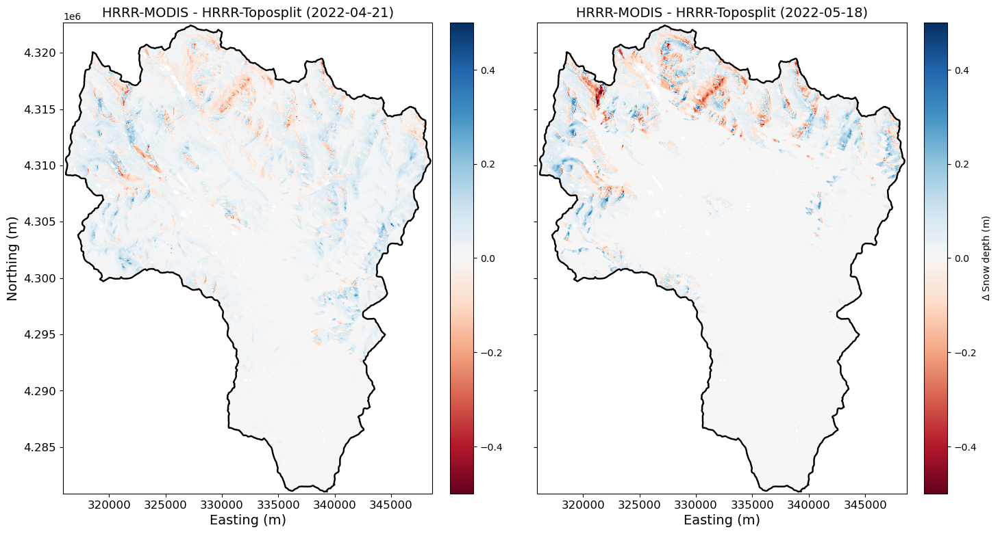

In [36]:
fig, axs = plt.subplots(1,2, figsize=(15, 8), sharey=True)
axs=axs.ravel()

vmin, vmax = -0.5, 0.5
extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
        aso_data_20220421.y.min(),aso_data_20220421.y.max()]

axs[0].set_title('HRRR-MODIS - HRRR-Toposplit ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img0 = axs[0].imshow(sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
img0 = axs[0].imshow(mod_dsw3_ch04,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

axs[1].set_title('HRRR-MODIS - HRRR-Toposplit ('+pd.to_datetime(aso_data_20220518.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img1 = axs[1].imshow(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)

img1 = axs[1].imshow(mod_dsw3_ch05,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Snow depth (m)')

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

axs[0].set_ylabel("Northing (m)", fontsize=14)

for ax in axs:
    ax.set_xlabel("Easting (m)", fontsize=14)

# For better visualization
for ax in axs:
    ax.set_xlim(sd_toposplit_dsw3_20220518.x.min(), sd_toposplit_dsw3_20220518.x.max())
    ax.set_ylim(sd_toposplit_dsw3_20220518.y.min(), sd_toposplit_dsw3_20220518.y.max())


fig.tight_layout()

In [ ]:
import seaborn as sns

# Calculate bias (Model - Observed) and flatten to 1D
bias_20220421 = (sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.isel(time=0)).values.flatten()
bias_20220518 = (sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0)).values.flatten()

import pandas as pd

# Combine into a single DataFrame
bias_df = pd.DataFrame({
    'Bias': np.concatenate([bias_20220421, bias_20220518]),
    'Date': ['2022-04-21'] * len(bias_20220421) + ['2022-05-18'] * len(bias_20220518)
})

bias_df = bias_df[(bias_df['Bias'] >= -2) & (bias_df['Bias'] <= 2)]

fig, ax = plt.subplots(figsize=(6, 8))

sns.violinplot(data=bias_df, x='Date', y='Bias', palette='RdBu', ax=ax)
ax.axhline(0, color='k', linestyle='--', linewidth=1)
sns.pointplot(data=bias_df, x='Date', y='Bias', estimator=np.mean, color='black', ax=ax, markers='o', errorbar=None, join=False)
ax.set_title("HRRR-TopoSplit - ASO", fontsize=14)
ax.set_ylabel("Bias in snow depth (m)", fontsize=14)
# ax.set_xlabel("Date", fontsize=14)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.show()
# svpth = "/uufs/chpc.utah.edu/common/home/u1037042/Documents/figures-2025/topo-split-rmgsa/"
# plt.savefig(svpth + 'aso-comp-dsw3-stats.png', dpi=300, bbox_inches='tight')

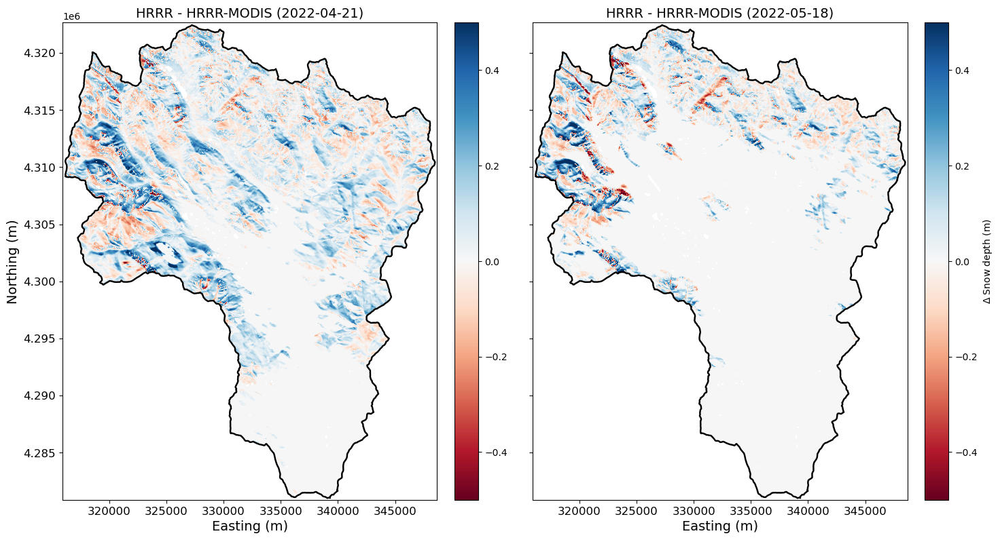

In [18]:
fig, axs = plt.subplots(1,2, figsize=(15, 8), sharey=True)
axs=axs.ravel()

vmin, vmax = -0.5, 0.5
extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
        aso_data_20220421.y.min(),aso_data_20220421.y.max()]

axs[0].set_title('HRRR - HRRR-MODIS ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img0 = axs[0].imshow(sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
img0 = axs[0].imshow(mod_dsw1_ch04,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

axs[1].set_title('HRRR - HRRR-MODIS ('+pd.to_datetime(aso_data_20220518.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img1 = axs[1].imshow(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)

img1 = axs[1].imshow(mod_dsw1_ch05,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Snow depth (m)')

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

axs[0].set_ylabel("Northing (m)", fontsize=14)

for ax in axs:
    ax.set_xlabel("Easting (m)", fontsize=14)

# For better visualization
for ax in axs:
    ax.set_xlim(sd_toposplit_dsw3_20220518.x.min(), sd_toposplit_dsw3_20220518.x.max())
    ax.set_ylim(sd_toposplit_dsw3_20220518.y.min(), sd_toposplit_dsw3_20220518.y.max())


fig.tight_layout()

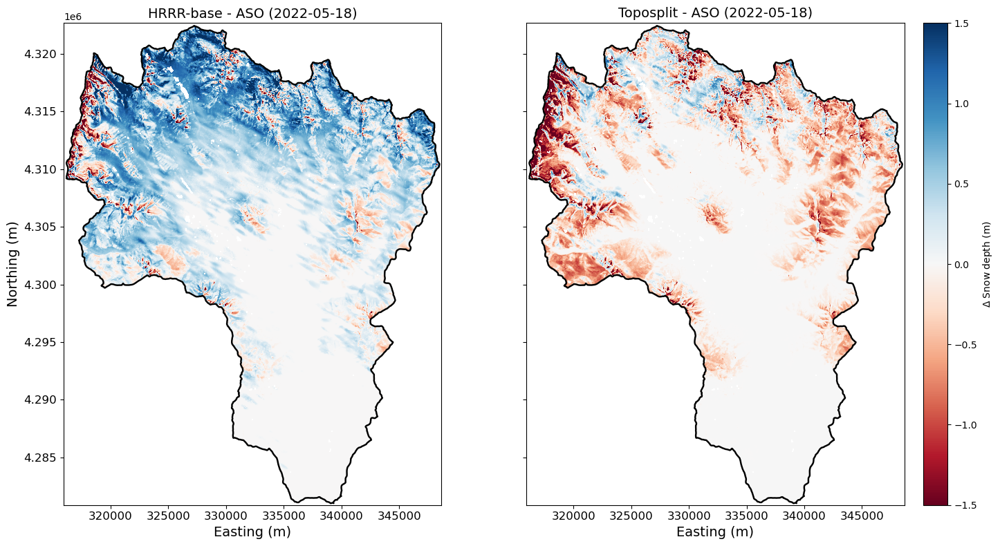

In [23]:
fig, axs = plt.subplots(1,2, figsize=(15, 8), sharey=True)
axs=axs.ravel()

vmin, vmax = -1.5, 1.5
extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
        aso_data_20220421.y.min(),aso_data_20220421.y.max()]

axs[0].set_title('HRRR-base - ASO ('+pd.to_datetime(aso_data_20220518.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img0 = axs[0].imshow(sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
img0 = axs[0].imshow(mb5,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
# fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

axs[1].set_title('Toposplit - ASO ('+pd.to_datetime(aso_data_20220518.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img1 = axs[1].imshow(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.snow_depth.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)

img1 = axs[1].imshow(ms5,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Snow depth (m)')

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

axs[0].set_ylabel("Northing (m)", fontsize=14)

for ax in axs:
    ax.set_xlabel("Easting (m)", fontsize=14)

# For better visualization
for ax in axs:
    ax.set_xlim(sd_toposplit_dsw3_20220518.x.min(), sd_toposplit_dsw3_20220518.x.max())
    ax.set_ylim(sd_toposplit_dsw3_20220518.y.min(), sd_toposplit_dsw3_20220518.y.max())


fig.tight_layout()

svpth = "/uufs/chpc.utah.edu/common/home/u1037042/Documents/figures-2025/topo-split-rmgsa/"
# plt.savefig(svpth + 'aso-comp-base-topo-05.png', dpi=300, bbox_inches='tight')

/scratch/local/u1037042/4416532/ipykernel_1662926/562927940.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=bias_df, x='Model', y='Bias', palette='RdBu', ax=ax)
/scratch/local/u1037042/4416532/ipykernel_1662926/562927940.py:21: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(data=bias_df, x='Model', y='Bias', estimator=np.mean, color='black', ax=ax, markers='o', errorbar=None, join=False)


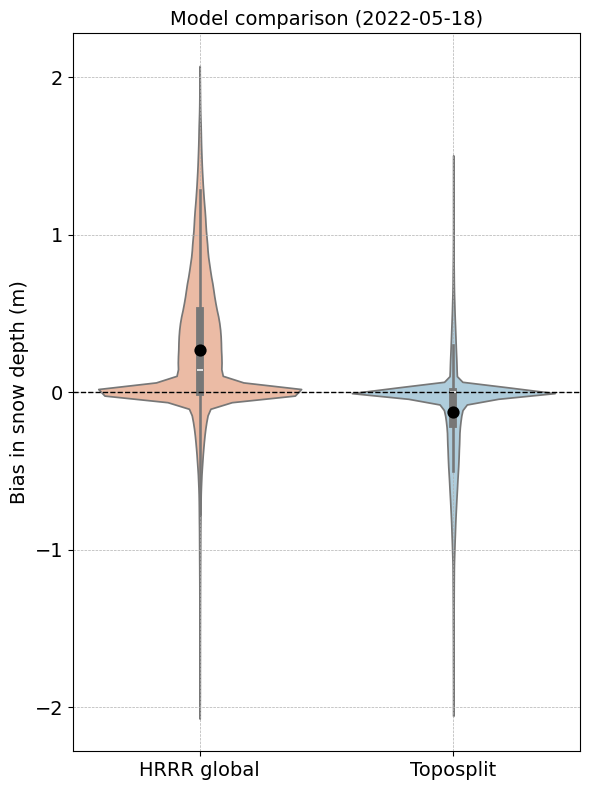

In [24]:
import seaborn as sns

# Calculate bias (Model - Observed) and flatten to 1D
bias_20220421 = mb5.values.flatten()
bias_20220518 = ms5.values.flatten()

import pandas as pd

# Combine into a single DataFrame
bias_df = pd.DataFrame({
    'Bias': np.concatenate([bias_20220421, bias_20220518]),
    'Model': ['HRRR global'] * len(bias_20220421) + ['Toposplit'] * len(bias_20220518)
})

bias_df = bias_df[(bias_df['Bias'] >= -2) & (bias_df['Bias'] <= 2)]

fig, ax = plt.subplots(figsize=(6, 8))

sns.violinplot(data=bias_df, x='Model', y='Bias', palette='RdBu', ax=ax)
ax.axhline(0, color='k', linestyle='--', linewidth=1)
sns.pointplot(data=bias_df, x='Model', y='Bias', estimator=np.mean, color='black', ax=ax, markers='o', errorbar=None, join=False)
ax.set_title("Model comparison (2022-05-18)", fontsize=14)
ax.set_ylabel("Bias in snow depth (m)", fontsize=14)
ax.set_xlabel("", fontsize=14)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.show()
# svpth = "/uufs/chpc.utah.edu/common/home/u1037042/Documents/figures-2025/topo-split-rmgsa/"
# plt.savefig(svpth + 'aso-comp-base-topo-05-stats.png', dpi=300, bbox_inches='tight')

In [27]:
# bias_df.groupby('Model').mean()
# bias_df.groupby('Model').median()

,Bias
Model,
HRRR global,0.139478
Toposplit,0.000000


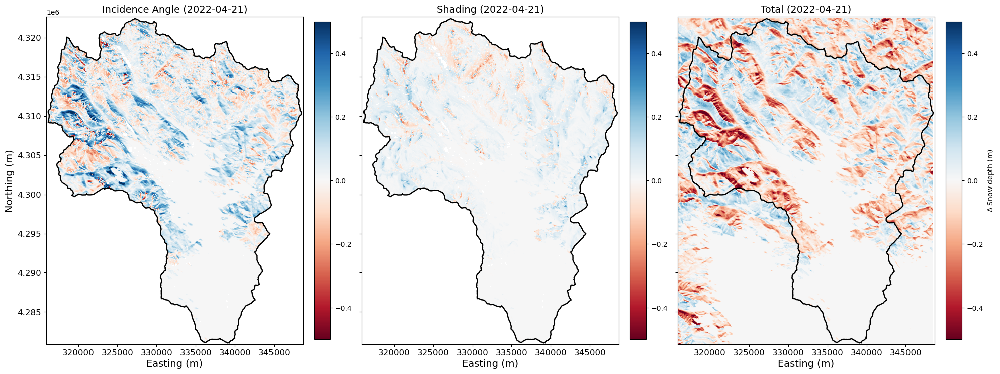

In [31]:
fig, axs = plt.subplots(1,3, figsize=(20, 8), sharey=True)
axs=axs.ravel()

vmin, vmax = -0.5, 0.5
extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
        aso_data_20220421.y.min(),aso_data_20220421.y.max()]


axs[0].set_title('Incidence Angle ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
img0 = axs[0].imshow(mod_dsw1_ch04,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

axs[1].set_title('Shading ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
img0 = axs[1].imshow(mod_dsw3_ch04,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img0, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04)

axs[2].set_title('Total ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
img1 = axs[2].imshow(mod_3diff_04,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[2], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[2], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Snow depth (m)')

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

axs[0].set_ylabel("Northing (m)", fontsize=14)

for ax in axs:
    ax.set_xlabel("Easting (m)", fontsize=14)

# For better visualization
for ax in axs:
    ax.set_xlim(sd_toposplit_dsw3_20220421.x.min(), sd_toposplit_dsw3_20220421.x.max())
    ax.set_ylim(sd_toposplit_dsw3_20220421.y.min(), sd_toposplit_dsw3_20220421.y.max())


fig.tight_layout()

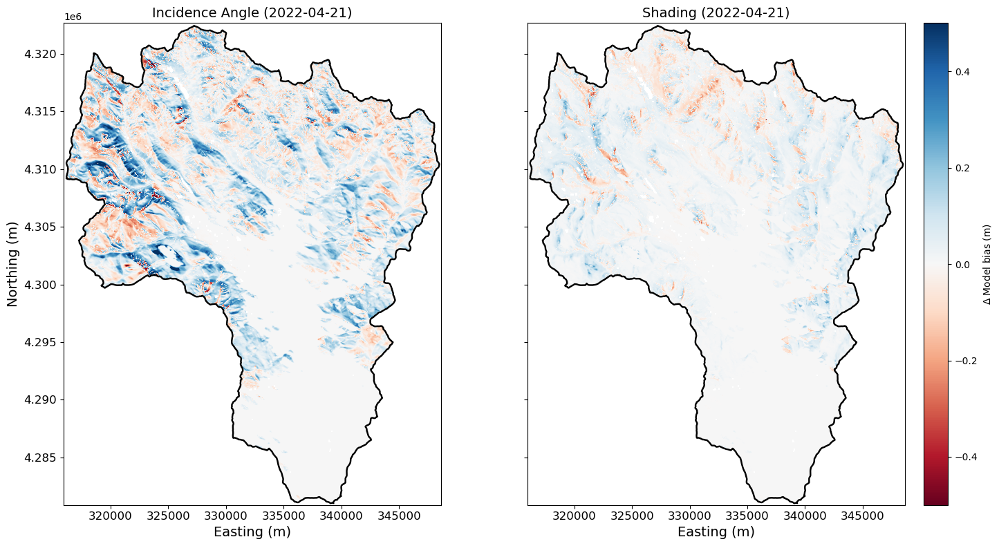

In [28]:
fig, axs = plt.subplots(1,2, figsize=(15, 8), sharey=True)
axs=axs.ravel()

vmin, vmax = -0.5, 0.5
extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
        aso_data_20220421.y.min(),aso_data_20220421.y.max()]


axs[0].set_title('Incidence Angle ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
img0 = axs[0].imshow(mod_dsw1_ch04,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
# fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

axs[1].set_title('Shading ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
img1 = axs[1].imshow(mod_dsw3_ch04,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Model bias (m)')

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

axs[0].set_ylabel("Northing (m)", fontsize=14)

for ax in axs:
    ax.set_xlabel("Easting (m)", fontsize=14)

# For better visualization
for ax in axs:
    ax.set_xlim(sd_toposplit_dsw3_20220421.x.min(), sd_toposplit_dsw3_20220421.x.max())
    ax.set_ylim(sd_toposplit_dsw3_20220421.y.min(), sd_toposplit_dsw3_20220421.y.max())


fig.tight_layout()

# svpth = "/uufs/chpc.utah.edu/common/home/u1037042/Documents/figures-2025/topo-split-rmgsa/"
# plt.savefig(svpth + 'aso-mod-bias-04.png', dpi=300, bbox_inches='tight')

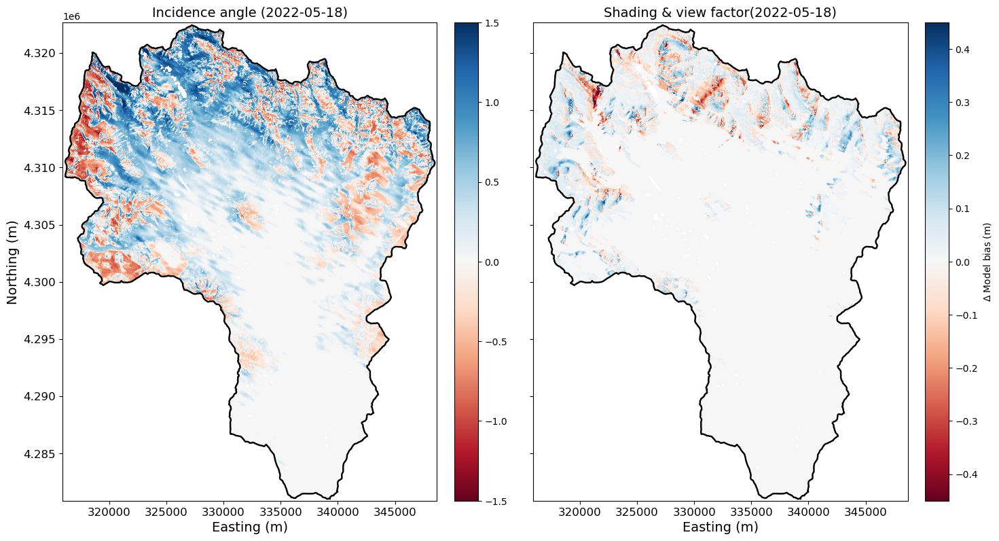

In [89]:
fig, axs = plt.subplots(1,2, figsize=(15, 8), sharey=True)
axs=axs.ravel()

vmin, vmax = -1.5, 1.5
vmin2, vmax2 = -0.45, 0.45
extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
        aso_data_20220421.y.min(),aso_data_20220421.y.max()]


axs[0].set_title('Incidence angle ('+pd.to_datetime(aso_data_20220518.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img0 = axs[0].imshow(mod_dsw1_ch05,
img0 = axs[0].imshow(np.abs(mb5) - np.abs(mc5),
# img0 = axs[0].imshow(np.abs(mb4) - np.abs(mc4),
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

axs[1].set_title('Shading & view factor('+pd.to_datetime(aso_data_20220518.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# img0 = axs[1].imshow(mod_dsw3_ch05,
img1 = axs[1].imshow(np.abs(mc5) - np.abs(ms5),
# img0 = axs[1].imshow(np.abs(mc4) - np.abs(ms4), #mod_dsw3_ch05,
                    vmin=vmin2, vmax=vmax2, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Model bias (m)')

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

axs[0].set_ylabel("Northing (m)", fontsize=14)

for ax in axs:
    ax.set_xlabel("Easting (m)", fontsize=14)

# For better visualization
for ax in axs:
    ax.set_xlim(sd_toposplit_dsw3_20220421.x.min(), sd_toposplit_dsw3_20220421.x.max())
    ax.set_ylim(sd_toposplit_dsw3_20220421.y.min(), sd_toposplit_dsw3_20220421.y.max())


fig.tight_layout()

# svpth = "/uufs/chpc.utah.edu/common/home/u1037042/Documents/figures-2025/topo-split-rmgsa/"
# plt.savefig(svpth + 'aso-mod-bias-05.png', dpi=300, bbox_inches='tight')

/scratch/local/u1037042/4416532/ipykernel_1662926/1642935717.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=bias_df, x='Model', y='Bias', palette='RdBu', ax=ax)
/scratch/local/u1037042/4416532/ipykernel_1662926/1642935717.py:24: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(data=bias_df, x='Model', y='Bias', estimator=np.mean, color='black', ax=ax, markers='o', errorbar=None, join=False)


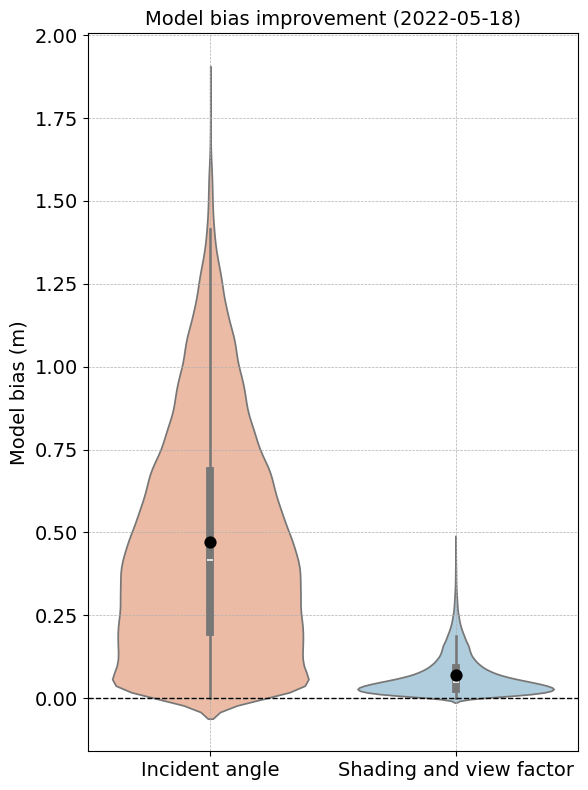

In [29]:
import seaborn as sns

# Calculate bias (Model - Observed) and flatten to 1D
bias_20220421 = (np.abs(mb5) - np.abs(mc5)).values.flatten()
bias_20220518 = (np.abs(mc5) - np.abs(ms5)).values.flatten()

bias_20220421 = bias_20220421[bias_20220421>0]
bias_20220518 = bias_20220518[bias_20220518>0]

import pandas as pd

# Combine into a single DataFrame
bias_df = pd.DataFrame({
    'Bias': np.concatenate([bias_20220421, bias_20220518]),
    'Model': ['Incident angle'] * len(bias_20220421) + ['Shading and view factor'] * len(bias_20220518)
})

bias_df = bias_df[(bias_df['Bias'] >= -2) & (bias_df['Bias'] <= 2)]

fig, ax = plt.subplots(figsize=(6, 8))

sns.violinplot(data=bias_df, x='Model', y='Bias', palette='RdBu', ax=ax)
ax.axhline(0, color='k', linestyle='--', linewidth=1)
sns.pointplot(data=bias_df, x='Model', y='Bias', estimator=np.mean, color='black', ax=ax, markers='o', errorbar=None, join=False)
ax.set_title("Model bias improvement (2022-05-18)", fontsize=14)
ax.set_ylabel("Model bias (m)", fontsize=14)
ax.set_xlabel("", fontsize=14)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.show()
# svpth = "/uufs/chpc.utah.edu/common/home/u1037042/Documents/figures-2025/topo-split-rmgsa/"
# plt.savefig(svpth + 'aso-mod-bias-05.png-stats.png', dpi=300, bbox_inches='tight')

In [16]:
import pandas as pd

# Assuming bias_df is already loaded as a DataFrame
# Here's how to calculate the statistics grouped by model:

bias_stats = bias_df.groupby('Model')['Bias'].agg(['mean', 'max', 'median'])
print(bias_stats)


                             mean       max    median
Model                                                
Incident angle           0.472382  1.845118  0.417165
Shading and view factor  0.068338  0.476498  0.047876


In [17]:
import pandas as pd

# Filter only positive bias values
positive_bias_df = bias_df[bias_df['Bias'] > 0]

# Define pixel area (m²)
pixel_area_m2 = 50 * 50

# Calculate water volume = Bias * Pixel Area
positive_bias_df['WaterVolume_m3'] = positive_bias_df['Bias'] * pixel_area_m2

# Group by model and sum total water volume
volume_estimates = positive_bias_df.groupby('Model')['WaterVolume_m3'].sum()

print(volume_estimates)


Model
Incident angle             172746560.0
Shading and view factor     10830220.0
Name: WaterVolume_m3, dtype: float32


In [23]:
bias_df

,Bias,Model
0,0.130739,Incident angle
1,0.969710,Incident angle
2,1.000306,Incident angle
3,0.933848,Incident angle
4,0.960902,Incident angle
...,...,...
209664,0.006432,Shading and view factor
209665,0.012149,Shading and view factor
209666,0.008929,Shading and view factor
209667,0.009740,Shading and view factor


In [28]:
import pandas as pd

# Filter for positive bias values only (snow depth improvements)
positive_bias_df = bias_df[bias_df['Bias'] > 0].copy()

# Constants
snow_density = 0.45  # 45% average snow density (unitless)
pixel_area_m2 = 50 * 50  # 2,500 m²
pixel_area_ha = pixel_area_m2 / 10_000  # 0.25 ha per pixel

# Unit conversions
m3_to_km3 = 1e-9  # m³ to km³

# Step 1: Convert snow depth bias to SWE (in meters)
positive_bias_df['SWE_m'] = positive_bias_df['Bias'] * snow_density

# Step 2: Calculate water volume per pixel (in m³)
positive_bias_df['WaterVolume_m3'] = positive_bias_df['SWE_m'] * pixel_area_m2

# Step 3: Group and aggregate
volume_by_model_km3 = positive_bias_df.groupby('Model')['WaterVolume_m3'].sum() * m3_to_km3
area_by_model_ha = positive_bias_df.groupby('Model').size() * pixel_area_ha

# Combine results into a table
results = pd.DataFrame({
    'Total Volume (km³)': volume_by_model_km3,
    'Total Area (ha)': area_by_model_ha
})

print(results)


                         Total Volume (km³)  Total Area (ha)
Model                                                       
Incident angle                     0.077736         36569.25
Shading and view factor            0.004874         15848.00


In [30]:
print(positive_bias_df[['Bias', 'SWE_m', 'WaterVolume_m3']].head())
# ORIGINAL (wrong way): using Bias directly
bias_df_pos = bias_df[bias_df['Bias'] > 0].copy()
bias_df_pos['VolumeFromBias'] = bias_df_pos['Bias'] * 2500

# CORRECT (SWE-adjusted)
bias_df_pos['VolumeFromSWE'] = bias_df_pos['Bias'] * 0.45 * 2500

# Compare both sums
print("Original volume (km³):", bias_df_pos['VolumeFromBias'].sum() / 1e9)
print("Corrected SWE volume (km³):", bias_df_pos['VolumeFromSWE'].sum() / 1e9)


       Bias     SWE_m  WaterVolume_m3
0  0.130739  0.058832      147.081131
1  0.969710  0.436370     1090.923828
2  1.000306  0.450138     1125.344604
3  0.933848  0.420232     1050.578857
4  0.960902  0.432406     1081.014526
Original volume (km³): 0.18357676
Corrected SWE volume (km³): 0.08260954


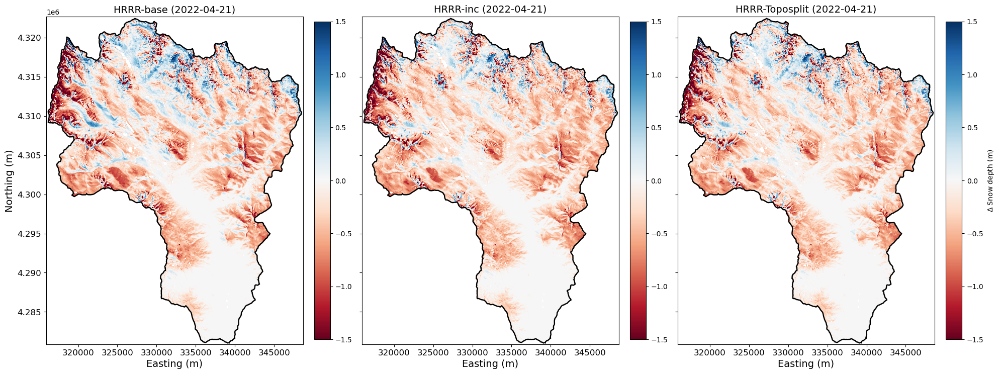

In [48]:
fig, axs = plt.subplots(1,3, figsize=(20, 8), sharey=True)
axs=axs.ravel()

vmin, vmax = -1.5, 1.5
vmin2, vmax2 = -.5, .5
extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
        aso_data_20220421.y.min(),aso_data_20220421.y.max()]


axs[0].set_title('HRRR-base ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
img0 = axs[0].imshow(mb4,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

axs[1].set_title('HRRR-inc ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
img0 = axs[1].imshow(mc4,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
fig.colorbar(img0, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04)

axs[2].set_title('HRRR-Toposplit ('+pd.to_datetime(aso_data_20220421.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
img1 = axs[2].imshow(ms4,
                    vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
erw_shp.boundary.plot(ax=axs[2], color='k', linewidth=1.75)
fig.colorbar(img1, ax=axs[2], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Snow depth (m)')

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

axs[0].set_ylabel("Northing (m)", fontsize=14)

for ax in axs:
    ax.set_xlabel("Easting (m)", fontsize=14)

# For better visualization
for ax in axs:
    ax.set_xlim(sd_toposplit_dsw3_20220421.x.min(), sd_toposplit_dsw3_20220421.x.max())
    ax.set_ylim(sd_toposplit_dsw3_20220421.y.min(), sd_toposplit_dsw3_20220421.y.max())


fig.tight_layout()

/scratch/local/u1037042/4373067/ipykernel_3944746/1948243917.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=bias_df, x='Model', y='Improvement', palette='RdBu', ax=ax)
/scratch/local/u1037042/4373067/ipykernel_3944746/1948243917.py:27: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(


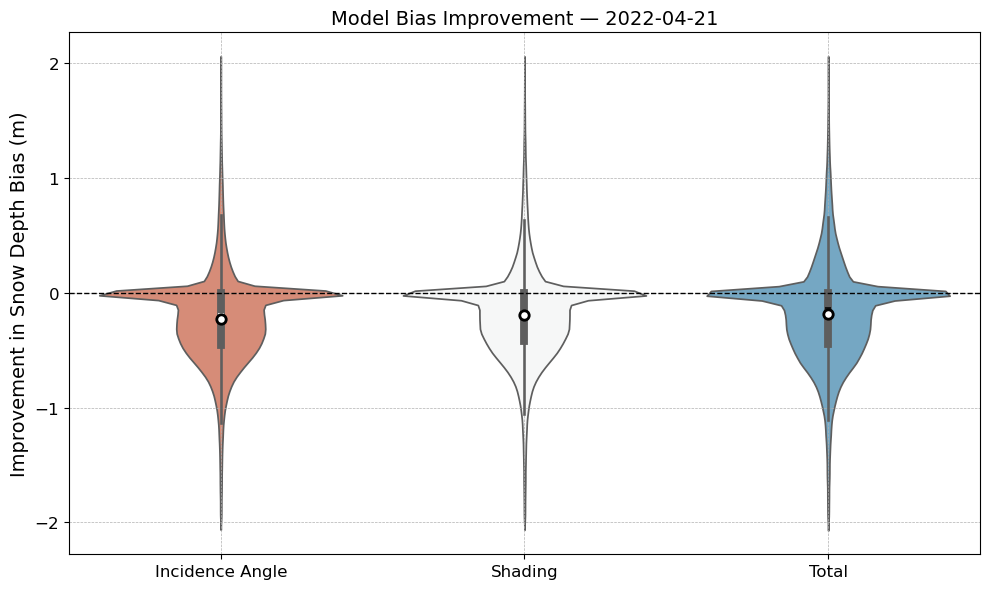

NameError: name 'impact_total_1' is not defined

In [49]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Flatten rasters for 2022-04-21
imp_cosi_20220421 = mc4.values.flatten()
imp_shade_20220421 = ms4.values.flatten()
imp_total_20220421 = mb4.values.flatten()

# Create a combined DataFrame
bias_df = pd.DataFrame({
    'Improvement': np.concatenate([imp_cosi_20220421, imp_shade_20220421, imp_total_20220421]),
    'Model': ['Incidence Angle'] * len(imp_cosi_20220421) + 
             ['Shading'] * len(imp_shade_20220421) + 
             ['Total'] * len(imp_total_20220421),
    'Date': ['2022-04-21'] * len(imp_total_20220421) * 3  # Assumes same shape for all
})

# Filter to range [-2, 2]
bias_df = bias_df[(bias_df['Improvement'] >= -2) & (bias_df['Improvement'] <= 2)]


fig, ax = plt.subplots(figsize=(10, 6))

sns.violinplot(data=bias_df, x='Model', y='Improvement', palette='RdBu', ax=ax)
sns.pointplot(
    data=bias_df,
    x='Model',
    y='Improvement',
    estimator=np.mean,
    color='black',
    ax=ax,
    markers='o',
    linestyles='',
    errorbar=None,
    join=False
)

# Make pointplot markers hollow
for line in ax.lines[-3:]:  # Adjust number if needed
    line.set_markerfacecolor('white')
    line.set_markeredgecolor('black')

# Formatting
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_title("Model Bias Improvement — 2022-04-21", fontsize=14)
ax.set_ylabel("Improvement in Snow Depth Bias (m)", fontsize=14)
ax.set_xlabel("")
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()


# Repeat for 2022-05-18
imp_cosi_20220518 = mod_dsw1_ch05.values.flatten()
imp_shade_20220518 = mod_dsw3_ch05.values.flatten()
imp_total_20220518 = impact_total_1.values.flatten()

bias_df_2 = pd.DataFrame({
    'Improvement': np.concatenate([imp_cosi_20220518, imp_shade_20220518, imp_total_20220518]),
    'Model': ['Incidence Angle'] * len(imp_cosi_20220518) + 
             ['Shading'] * len(imp_shade_20220518) + 
             ['Total'] * len(imp_total_20220518),
    'Date': ['2022-05-18'] * len(imp_total_20220518) * 3
})

# Merge both dates and filter
bias_df_all = pd.concat([bias_df, bias_df_2], ignore_index=True)
bias_df_all = bias_df_all[(bias_df_all['Improvement'] >= -2) & (bias_df_all['Improvement'] <= 2)]

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=bias_df_all, x='Model', y='Improvement', hue='Date', split=True, palette='RdBu', ax=ax)
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_title("Bias Improvement from Model Features", fontsize=14)
ax.set_ylabel("Improvement in Snow Depth Bias (m)", fontsize=14)
ax.set_xlabel("")
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.show()



/scratch/local/u1037042/4373067/ipykernel_3944746/259648972.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=bias_df, x='Model', y='Improvement', palette='RdBu', ax=ax)
/scratch/local/u1037042/4373067/ipykernel_3944746/259648972.py:27: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(


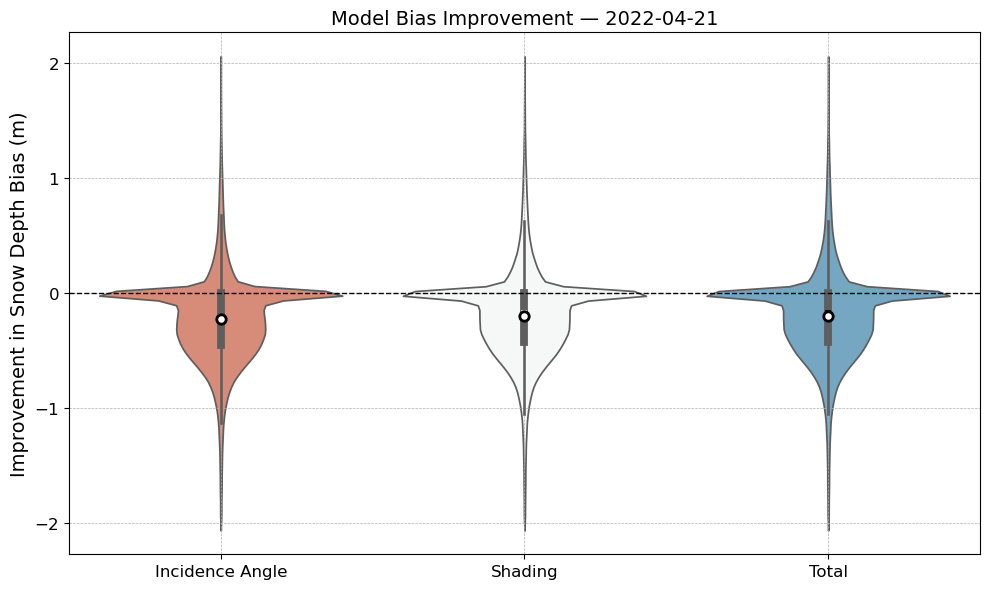

NameError: name 'impact_total_1' is not defined

In [34]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Flatten rasters for 2022-04-21
imp_cosi_20220421 = bias_dsw1_04.values.flatten()
imp_shade_20220421 = bias_dsw3_04.values.flatten()
imp_total_20220421 = bias_dsw3h_04.values.flatten()

# Create a combined DataFrame
bias_df = pd.DataFrame({
    'Improvement': np.concatenate([imp_cosi_20220421, imp_shade_20220421, imp_total_20220421]),
    'Model': ['Incidence Angle'] * len(imp_cosi_20220421) + 
             ['Shading'] * len(imp_shade_20220421) + 
             ['Total'] * len(imp_total_20220421),
    'Date': ['2022-04-21'] * len(imp_total_20220421) * 3  # Assumes same shape for all
})

# Filter to range [-2, 2]
bias_df = bias_df[(bias_df['Improvement'] >= -2) & (bias_df['Improvement'] <= 2)]


fig, ax = plt.subplots(figsize=(10, 6))

sns.violinplot(data=bias_df, x='Model', y='Improvement', palette='RdBu', ax=ax)
sns.pointplot(
    data=bias_df,
    x='Model',
    y='Improvement',
    estimator=np.mean,
    color='black',
    ax=ax,
    markers='o',
    linestyles='',
    errorbar=None,
    join=False
)

# Make pointplot markers hollow
for line in ax.lines[-3:]:  # Adjust number if needed
    line.set_markerfacecolor('white')
    line.set_markeredgecolor('black')

# Formatting
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_title("Model Bias Improvement — 2022-04-21", fontsize=14)
ax.set_ylabel("Improvement in Snow Depth Bias (m)", fontsize=14)
ax.set_xlabel("")
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()


# Repeat for 2022-05-18
imp_cosi_20220518 = mod_dsw1_ch05.values.flatten()
imp_shade_20220518 = mod_dsw3_ch05.values.flatten()
imp_total_20220518 = impact_total_1.values.flatten()

bias_df_2 = pd.DataFrame({
    'Improvement': np.concatenate([imp_cosi_20220518, imp_shade_20220518, imp_total_20220518]),
    'Model': ['Incidence Angle'] * len(imp_cosi_20220518) + 
             ['Shading'] * len(imp_shade_20220518) + 
             ['Total'] * len(imp_total_20220518),
    'Date': ['2022-05-18'] * len(imp_total_20220518) * 3
})

# Merge both dates and filter
bias_df_all = pd.concat([bias_df, bias_df_2], ignore_index=True)
bias_df_all = bias_df_all[(bias_df_all['Improvement'] >= -2) & (bias_df_all['Improvement'] <= 2)]

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=bias_df_all, x='Model', y='Improvement', hue='Date', split=True, palette='RdBu', ax=ax)
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_title("Bias Improvement from Model Features", fontsize=14)
ax.set_ylabel("Improvement in Snow Depth Bias (m)", fontsize=14)
ax.set_xlabel("")
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.show()



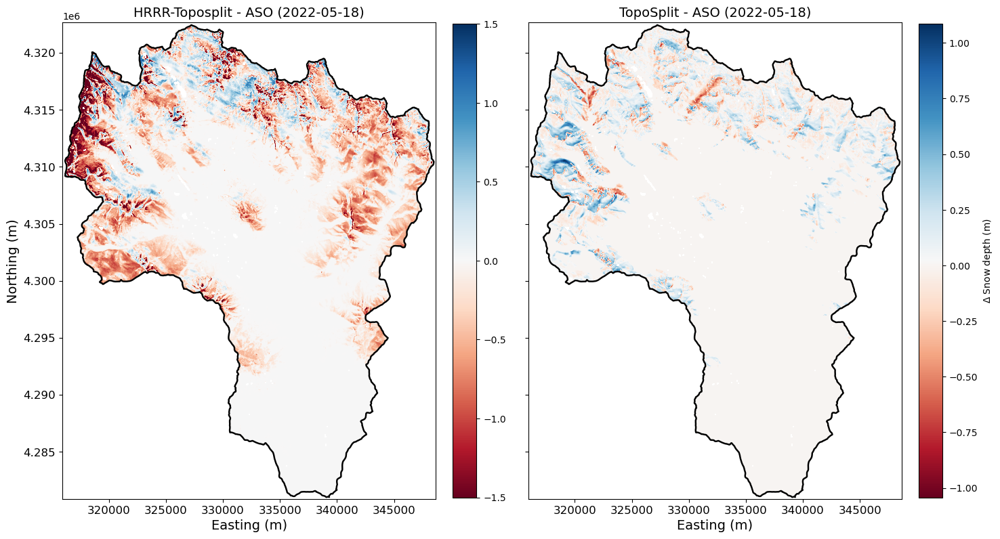

In [54]:
# fig, axs = plt.subplots(1,2, figsize=(15, 8), sharey=True)
# axs=axs.ravel()

# vmin, vmax = -1.5, 1.5
# extent=[aso_data_20220421.x.min(), aso_data_20220421.x.max(),
#         aso_data_20220421.y.min(),aso_data_20220421.y.max()]

# axs[0].set_title('HRRR-Toposplit - ASO ('+pd.to_datetime(aso_data_20220518.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# # img0 = axs[0].imshow(sd_toposplit_dsw3_20220421_repr.thickness.isel(time=0) - aso_data_20220421.snow_depth.isel(time=0),
# #                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
# img0 = axs[0].imshow(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.isel(time=0),
#                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)
# erw_shp.boundary.plot(ax=axs[0], color='k', linewidth=1.75)
# fig.colorbar(img0, ax=axs[0], orientation='vertical', fraction=0.056, pad=0.04)

# axs[1].set_title('TopoSplit - ASO ('+pd.to_datetime(aso_data_20220518.time.values[0]).strftime('%Y-%m-%d')+')', fontsize=14)
# # img1 = axs[1].imshow(sd_toposplit_dsw3_20220518_repr.thickness.isel(time=0) - aso_data_20220518.snow_depth.isel(time=0),
# #                     vmin=vmin, vmax=vmax, cmap='RdBu', extent=extent)


# img1 = axs[1].imshow(impact_total_05,
#                     cmap='RdBu', extent=extent)
# erw_shp.boundary.plot(ax=axs[1], color='k', linewidth=1.75)
# fig.colorbar(img1, ax=axs[1], orientation='vertical', fraction=0.056, pad=0.04, label=r'$\Delta$ Snow depth (m)')

# for ax in axs:
#     ax.tick_params(axis='both', labelsize=12)  # Increase tick label size

# axs[0].set_ylabel("Northing (m)", fontsize=14)

# for ax in axs:
#     ax.set_xlabel("Easting (m)", fontsize=14)

# # For better visualization
# for ax in axs:
#     ax.set_xlim(sd_toposplit_dsw3_20220518.x.min(), sd_toposplit_dsw3_20220518.x.max())
#     ax.set_ylim(sd_toposplit_dsw3_20220518.y.min(), sd_toposplit_dsw3_20220518.y.max())


# fig.tight_layout()